# 식단 추천 서비스 데이터 EDA
## 0. 분석 목표
- 질문: 어떤 건강 상태와 생활 습관을 가진 사람에게 어떤 식단이 추천되는가?
- 데이터: 5,000명의 건강·생활습관 정보와 추천된 식단(Diet_Recommendation)

## 1.데이터 불러오기

In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\user\OneDrive\Desktop\Data\diet_recommendations.csv") #윈도우일 경우 문자열 앞에 r 붙이기
df.head() #상위 5행만 출력

,Patient_ID,Age,Gender,Weight_kg,Height_cm,Physical_Activity_Level,Daily_Caloric_Intake,Cholesterol_mg/dL,Blood_Pressure_mmHg,Glucose_mg/dL,Dietary_Restrictions,Allergies,Preferred_Cuisine,Weekly_Exercise_Hours,Adherence_to_Diet_Plan,Dietary_Nutrient_Imbalance_Score,Diet_Recommendation
0,P0001,56,Male,114.1,190.0,Moderate,3140,212.1,153.8,125.6,Low_Sugar,Gluten,Indian,4.94,1.0,1.7,Low_Sodium
1,P0002,69,Female,66.1,163.0,Sedentary,1801,183.5,140.4,129.6,NaN,Peanuts,Italian,1.74,1.0,0.8,Balanced
2,P0003,46,Female,58.0,159.2,Sedentary,1869,245.8,112.4,91.6,Low_Sugar,Peanuts,Chinese,2.53,1.0,4.5,Balanced
3,P0004,32,Female,84.5,163.9,Sedentary,2094,147.3,146.1,129.3,Low_Sodium,NaN,Indian,2.11,1.0,0.5,Balanced
4,P0005,60,Female,79.3,169.1,Moderate,2222,245.0,145.8,128.6,Low_Sugar,Peanuts,Chinese,6.00,1.0,3.8,Balanced


## 2. 데이터 탐색 및 전처리

### 2-1. 데이터 구조 파악

In [2]:
df.columns #전체 컬럼들의 이름을 확인

Index(['Patient_ID', 'Age', 'Gender', 'Weight_kg', 'Height_cm',
       'Physical_Activity_Level', 'Daily_Caloric_Intake', 'Cholesterol_mg/dL',
       'Blood_Pressure_mmHg', 'Glucose_mg/dL', 'Dietary_Restrictions',
       'Allergies', 'Preferred_Cuisine', 'Weekly_Exercise_Hours',
       'Adherence_to_Diet_Plan', 'Dietary_Nutrient_Imbalance_Score',
       'Diet_Recommendation'],
      dtype='str')

In [3]:
df.shape #데이터의 크기(행 개수, 열 개수)

(5000, 17)

In [4]:
df.info() #각 컬럼의 자료형과 결측값 존재 여부를 확인

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Patient_ID                        5000 non-null   str    
 1   Age                               5000 non-null   int64  
 2   Gender                            5000 non-null   str    
 3   Weight_kg                         5000 non-null   float64
 4   Height_cm                         5000 non-null   float64
 5   Physical_Activity_Level           5000 non-null   str    
 6   Daily_Caloric_Intake              5000 non-null   int64  
 7   Cholesterol_mg/dL                 5000 non-null   float64
 8   Blood_Pressure_mmHg               5000 non-null   float64
 9   Glucose_mg/dL                     5000 non-null   float64
 10  Dietary_Restrictions              2915 non-null   str    
 11  Allergies                         3286 non-null   str    
 12  Preferred_Cuisine

In [5]:
df.describe() #평균, 표준편차, 최소값, 최대값, 사분위수(25%, 50%, 75%) 등을 확인

,Age,Weight_kg,Height_cm,Daily_Caloric_Intake,Cholesterol_mg/dL,Blood_Pressure_mmHg,Glucose_mg/dL,Weekly_Exercise_Hours,Adherence_to_Diet_Plan,Dietary_Nutrient_Imbalance_Score
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,5000.00000
mean,48.805600,79.525640,166.015560,2352.401800,198.091180,144.285060,123.595260,6.127316,1.0,2.51184
std,17.906991,18.156126,8.677272,409.095301,40.494133,12.159795,15.838408,3.564555,0.0,1.43428
min,18.000000,31.600000,145.000000,1660.000000,111.600000,105.000000,53.000000,0.800000,1.0,0.00000
25%,34.000000,65.700000,159.500000,1998.000000,169.075000,142.000000,118.700000,2.250000,1.0,1.30000
50%,49.000000,81.300000,165.400000,2290.500000,197.950000,147.800000,127.800000,6.140000,1.0,2.50000
75%,64.000000,93.500000,172.325000,2705.000000,226.425000,152.200000,133.300000,9.342500,1.0,3.80000
max,79.000000,141.800000,190.000000,3140.000000,300.000000,167.400000,192.600000,12.600000,1.0,5.00000


### 2-2. 결측값과 중복 데이터 확인

In [6]:
df.isna().sum() #각 컬럼별 결측값 개수를 확인

Patient_ID                             0
Age                                    0
Gender                                 0
Weight_kg                              0
Height_cm                              0
Physical_Activity_Level                0
Daily_Caloric_Intake                   0
Cholesterol_mg/dL                      0
Blood_Pressure_mmHg                    0
Glucose_mg/dL                          0
Dietary_Restrictions                2085
Allergies                           1714
Preferred_Cuisine                      0
Weekly_Exercise_Hours                  0
Adherence_to_Diet_Plan                 0
Dietary_Nutrient_Imbalance_Score       0
Diet_Recommendation                    0
dtype: int64

In [7]:
df.duplicated().sum() #완전히 중복된 행이 몇 개 있는지 확인

np.int64(0)

### 2-3. 결측값 처리와 상수 컬럼 확인

In [8]:
# 결측값 비율(%): 개수만 보면 전체에서 얼마나 큰지 알기 어려워서 비율로도 확인
(df.isna().mean() * 100).round(1)

Patient_ID                           0.0
Age                                  0.0
Gender                               0.0
Weight_kg                            0.0
Height_cm                            0.0
Physical_Activity_Level              0.0
Daily_Caloric_Intake                 0.0
Cholesterol_mg/dL                    0.0
Blood_Pressure_mmHg                  0.0
Glucose_mg/dL                        0.0
Dietary_Restrictions                41.7
Allergies                           34.3
Preferred_Cuisine                    0.0
Weekly_Exercise_Hours                0.0
Adherence_to_Diet_Plan               0.0
Dietary_Nutrient_Imbalance_Score     0.0
Diet_Recommendation                  0.0
dtype: float64

In [9]:
# 결측값 처리: 데이터 설명에 결측의 의미가 적혀 있지 않아서 행을 지우거나 '없음'이라고 단정하지 않고,
# 'Not_Specified'라는 별도 범주로 둔다 (정보 손실을 막기 위해)
df["Dietary_Restrictions"] = df["Dietary_Restrictions"].fillna("Not_Specified")
df["Allergies"] = df["Allergies"].fillna("Not_Specified")
df.isna().sum().sum()  # 0이 나오면 결측값이 모두 처리된 것

np.int64(0)

In [10]:
# 컬럼별 서로 다른 값의 개수: 1이면 모든 행의 값이 같은 컬럼이라 그룹 간 차이를 설명하지 못한다
df.nunique().sort_values()

Adherence_to_Diet_Plan                 1
Gender                                 2
Allergies                              3
Physical_Activity_Level                3
Dietary_Restrictions                   3
Diet_Recommendation                    3
Preferred_Cuisine                      4
Dietary_Nutrient_Imbalance_Score      51
Age                                   62
Height_cm                            416
Blood_Pressure_mmHg                  524
Glucose_mg/dL                        651
Weight_kg                            814
Weekly_Exercise_Hours                919
Daily_Caloric_Intake                1350
Cholesterol_mg/dL                   1513
Patient_ID                          5000
dtype: int64

### 2-4. 파생 변수 만들기

In [11]:
#BMI를 계산하는 컬럼 생성 
df["BMI"] = df["Weight_kg"] / (df["Height_cm"] / 100) ** 2 

In [12]:
#BMI를 기준으로 체중 상태를 분류하는 BMI_Category 컬럼만들기
def categorize_bmi(bmi):
    if bmi < 18.5:
        return "Underweight"   # 저체중
    elif bmi < 25:
        return "Normal"        # 정상
    elif bmi < 30:
        return "Overweight"    # 과체중
    else:
        return "Obese"         # 비만

df["BMI_Category"] = df["BMI"].apply(categorize_bmi)

In [13]:
#Age_Group 만들기
bins = [18, 35, 50, 65, 80]
labels = ["18_34", "35_49", "50_64", "65_79"]

df["Age_Group"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)

In [14]:
#Metabolic_Risk_Score 만들기
#각 건강 지표별로 고위험군을 구분
#High_Chol: 콜레스테롤 ≥ 240mg/dL 이면 1, 아니면 0
#High_BP: 혈압 ≥ 140mmHg 이면 1, 아니면 0
#High_Glucose: 혈당 ≥ 126mg/dL 이면 1, 아니면 0
#세 개의 변수를 더해서 Metabolic_Risk_Score라는 통합 점수를 생성

#값은 0~3 사이이며, 숫자가 클수록 대사 위험이 더 높은 상태를 의미
df["High_Chol"] = (df["Cholesterol_mg/dL"] >= 240).astype(int)
df["High_BP"] = (df["Blood_Pressure_mmHg"] >= 140).astype(int)
df["High_Glucose"] = (df["Glucose_mg/dL"] >= 126).astype(int)
df["Metabolic_Risk_Score"] = df["High_Chol"] + df["High_BP"] + df["High_Glucose"]

### 2-5. 주요 수치형 컬럼들의 분포 확인

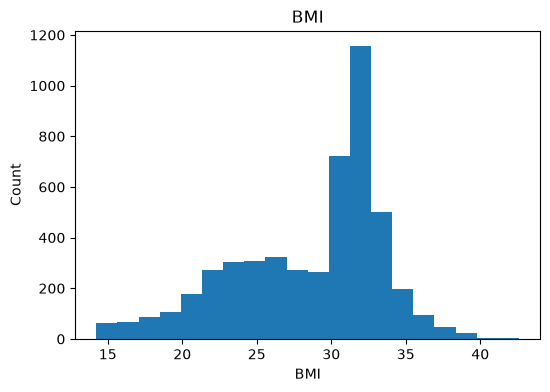

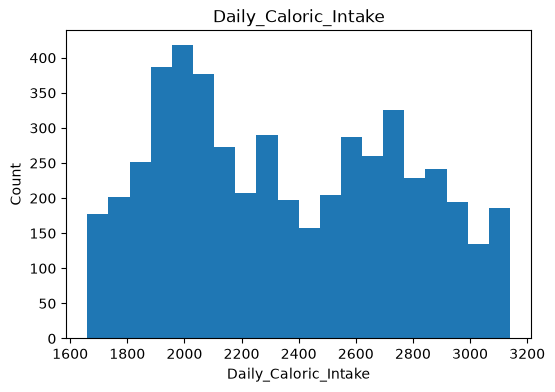

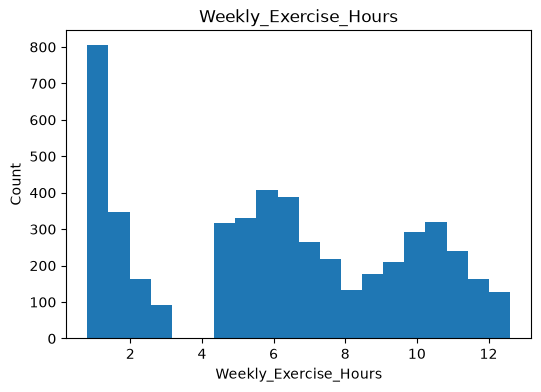

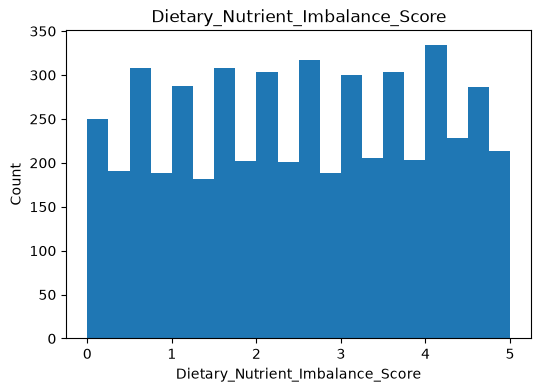

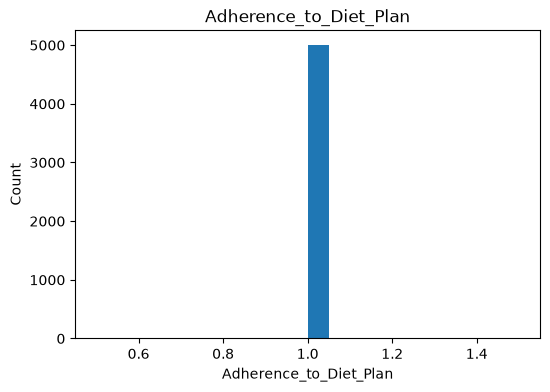

In [15]:
import matplotlib.pyplot as plt

# 히스토그램: 값을 구간(막대)으로 나눠서 어느 구간에 데이터가 많이 몰려 있는지 본다
num_cols = ["BMI", "Daily_Caloric_Intake", "Weekly_Exercise_Hours",
            "Dietary_Nutrient_Imbalance_Score", "Adherence_to_Diet_Plan"]

for c in num_cols:  # 컬럼마다 같은 작업을 반복하므로 for문으로 묶는다
    plt.figure(figsize=(6, 4))
    plt.hist(df[c], bins=20)  # bins는 막대 개수: 너무 적으면 모양이 뭉개지고 너무 많으면 들쭉날쭉해진다
    plt.title(c)
    plt.xlabel(c)
    plt.ylabel("Count")
    plt.show()

### 2-6. 주요 범주형 컬럼들의 분포 확인

In [16]:
# value_counts: 각 값이 몇 번 나오는지 센다. 어떤 범주가 많고 적은지 분석 전에 알아두기 위한 단계
cat_cols = ["Gender", "Physical_Activity_Level", "Dietary_Restrictions", "Allergies",
            "Preferred_Cuisine", "Diet_Recommendation", "Age_Group", "BMI_Category"]

for c in cat_cols:
    print(df[c].value_counts())
    print()

Gender
Female    2506
Male      2494
Name: count, dtype: int64

Physical_Activity_Level
Moderate     1928
Active       1662
Sedentary    1410
Name: count, dtype: int64

Dietary_Restrictions
Not_Specified    2085
Low_Sugar        1488
Low_Sodium       1427
Name: count, dtype: int64

Allergies
Peanuts          1797
Not_Specified    1714
Gluten           1489
Name: count, dtype: int64

Preferred_Cuisine
Indian     1298
Chinese    1254
Italian    1239
Mexican    1209
Name: count, dtype: int64

Diet_Recommendation
Balanced      2794
Low_Sodium    1229
Low_Carb       977
Name: count, dtype: int64

Age_Group
18_34    1324
50_64    1237
65_79    1227
35_49    1212
Name: count, dtype: int64

BMI_Category
Obese          2724
Normal         1032
Overweight     1032
Underweight     212
Name: count, dtype: int64



### 2-7. 이상치 확인

In [17]:
# 이상치: 다른 값들에 비해 유독 크거나 작게 튀는 값
# IQR 방식: 데이터를 크기순으로 줄 세웠을 때 가운데 50% 구간(Q1~Q3)의 폭을 IQR이라 하고,
# Q1 - 1.5*IQR 보다 작거나 Q3 + 1.5*IQR 보다 큰 값을 이상치 후보로 본다
check_cols = ["Age", "Weight_kg", "Height_cm", "Daily_Caloric_Intake", "Cholesterol_mg/dL",
              "Blood_Pressure_mmHg", "Glucose_mg/dL", "Weekly_Exercise_Hours",
              "Dietary_Nutrient_Imbalance_Score", "BMI"]

rows = []
for c in check_cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df[c] < lower) | (df[c] > upper)).sum()
    rows.append([c, round(lower, 2), round(upper, 2), n_out, round(n_out / len(df) * 100, 1)])

pd.DataFrame(rows, columns=["컬럼", "하한", "상한", "이상치 개수", "비율(%)"])

,컬럼,하한,상한,이상치 개수,비율(%)
0,Age,-11.00,109.00,0,0.0
1,Weight_kg,24.00,135.20,1,0.0
2,Height_cm,140.26,191.56,0,0.0
3,Daily_Caloric_Intake,937.50,3765.50,0,0.0
4,Cholesterol_mg/dL,83.05,312.45,0,0.0
5,Blood_Pressure_mmHg,126.70,167.50,542,10.8
6,Glucose_mg/dL,96.80,155.20,560,11.2
7,Weekly_Exercise_Hours,-8.39,19.98,0,0.0
8,Dietary_Nutrient_Imbalance_Score,-2.45,7.55,0,0.0
9,BMI,14.35,42.91,27,0.5


**이상치 처리 결정: 삭제하지 않고 유지**
- 혈압 542개(10.8%), 혈당 560개(11.2%), BMI 27개(0.5%), 체중 1개가 IQR 기준 이상치 후보로 확인됨
- 측정값 범위가 측정 오류로 보기 어렵고, 혈압·혈당은 고위험군 판정 기준(140, 126)에 쓰이는 지표라 삭제 시 고위험군이 사라지므로 유지

## 3. 데이터 분석
### 3-1. 어떤 사람에게 어떤 식단이 추천될까?

In [18]:
# groupby: 같은 값끼리 묶어서 계산하는 기능. 여기서는 추천된 식단 종류별로 묶어서 평균을 낸다
df.groupby("Diet_Recommendation")[["BMI", "Blood_Pressure_mmHg", "Glucose_mg/dL"]].mean().round(2)

,BMI,Blood_Pressure_mmHg,Glucose_mg/dL
Diet_Recommendation,,,
Balanced,27.86,139.80,119.78
Low_Carb,32.08,147.34,138.86
Low_Sodium,27.57,152.05,120.12


### 3-2. 활동 수준별 건강 지표 비교

In [19]:
df.groupby("Physical_Activity_Level")[["BMI", "Weekly_Exercise_Hours"]].mean().round(2)

,BMI,Weekly_Exercise_Hours
Physical_Activity_Level,,
Active,28.67,10.26
Moderate,28.52,5.98
Sedentary,28.66,1.46


### 3-3. 성별에 따른 건강 지표 비교

In [20]:
df.groupby("Gender")[["Height_cm", "Weight_kg", "BMI", "Daily_Caloric_Intake", "Weekly_Exercise_Hours"]].mean().round(2)

,Height_cm,Weight_kg,BMI,Daily_Caloric_Intake,Weekly_Exercise_Hours
Gender,,,,,
Female,160.21,67.31,26.19,1998.75,5.80
Male,171.85,91.80,31.04,2707.76,6.46


### 3-4. 연령대와 성별에 따른 건강 지표 변화

In [21]:
# 피벗테이블: 행(연령대)과 열(성별)로 표를 만들어 교차 평균을 한눈에 보는 방법
pd.pivot_table(
    df,
    index="Age_Group",
    columns="Gender",
    values=["BMI", "Blood_Pressure_mmHg", "Glucose_mg/dL", "Metabolic_Risk_Score"],
    aggfunc="mean",
    observed=True
).round(2)

BMI        Blood_Pressure_mmHg         Glucose_mg/dL          \
Gender    Female   Male              Female    Male        Female    Male   
Age_Group                                                                   
18_34      26.31  27.70              136.11  138.95        112.25  114.92   
35_49      26.27  32.22              135.19  149.23        111.18  130.68   
50_64      26.08  32.40              148.75  149.18        129.85  130.74   
65_79      26.12  32.33              148.69  149.46        130.50  130.58   

          Metabolic_Risk_Score        
Gender                  Female  Male  
Age_Group                             
18_34                     0.92  1.11  
35_49                     0.92  1.88  
50_64                     1.88  1.86  
65_79                     1.91  1.86

### 3-5. BMI 범주별 건강 지표 비교

In [22]:
df.groupby("BMI_Category")[["Blood_Pressure_mmHg", "Glucose_mg/dL",
                            "Metabolic_Risk_Score", "Dietary_Nutrient_Imbalance_Score"]].mean().round(2)

,Blood_Pressure_mmHg,Glucose_mg/dL,Metabolic_Risk_Score,Dietary_Nutrient_Imbalance_Score
BMI_Category,,,,
Normal,132.79,106.67,0.98,2.52
Obese,149.56,132.16,1.92,2.50
Overweight,142.69,119.60,1.11,2.48
Underweight,140.20,115.42,1.23,2.74


### 3-6. 관리가 필요한 그룹 찾기

In [23]:
# 앉아서 생활(Sedentary)하면서 비만(BMI 30 이상)인 사람을 집중 관리 그룹으로 정의
df["High_Risk_Group"] = (df["Physical_Activity_Level"] == "Sedentary") & (df["BMI"] >= 30)

print(df["High_Risk_Group"].value_counts())  # 그룹 인원수 (True가 집중 관리 그룹)
df.groupby("High_Risk_Group")[["BMI", "Weekly_Exercise_Hours", "Daily_Caloric_Intake"]].mean().round(2)

High_Risk_Group
False    4283
True      717
Name: count, dtype: int64


,BMI,Weekly_Exercise_Hours,Daily_Caloric_Intake
High_Risk_Group,,,
False,27.97,6.91,2325.96
True,32.45,1.47,2510.33


## 4. 결론 및 한계

### 결론
- **식단별 특징**: 저탄수화물(Low_Carb) 추천군은 평균 BMI 32.08, 평균 혈당 138.86으로 세 식단 중 가장 높았고, 저염분(Low_Sodium) 추천군은 평균 혈압 152.05로 가장 높았다. 균형식(Balanced) 추천군은 BMI 27.86, 혈압 139.80, 혈당 119.78이었다.
- **활동 수준**: 활동 수준별 평균 BMI는 28.52~28.67로 거의 차이가 없었고, 주당 운동시간만 Active 10.26시간, Moderate 5.98시간, Sedentary 1.46시간으로 크게 달랐다.
- **성별**: 남성이 여성보다 평균 체중(91.80kg vs 67.31kg), BMI(31.04 vs 26.19), 하루 섭취 칼로리(2707.76 vs 1998.75)가 높았다.
- **연령대×성별**: 여성은 50세 이상부터 평균 혈압(135.19→148.75)과 혈당(111.18→129.85), 대사 위험 점수(0.92→1.88)가 크게 올랐다. 남성은 18-34세(위험 점수 1.11)에서 35-49세(1.88)로 넘어갈 때 크게 올랐고 이후는 비슷한 수준(1.86에서 1.88 사이)이었다.
- **BMI 범주**: 비만(Obese) 범주는 평균 혈압 149.56, 혈당 132.16, 대사 위험 점수 1.92로 정상(Normal) 범주(132.79, 106.67, 0.98)보다 높았다.
- **집중 관리 그룹(좌식 + BMI 30 이상)**: 5,000명 중 717명(14.3%)이었다. 나머지 그룹과 비교해 평균 BMI 32.45 vs 27.97, 주당 운동시간 1.47시간 vs 6.91시간, 하루 섭취 칼로리 2510.33 vs 2325.96이었다.

### 한계
- 그룹별 평균만 비교했고 통계 검정은 하지 않아, 평균 차이가 우연이 아닌지는 확인하지 못했다. 원인과 결과를 단정할 수 없다.
- 식단 추천이 어떤 기준으로 생성되었는지 데이터 설명에 없어서, 추천 결과를 만든 규칙은 알 수 없다.
- Adherence_to_Diet_Plan은 모든 값이 같아 분석에서 제외했다.
- Dietary_Restrictions·Allergies의 결측(각 41.7%, 34.3%)은 의미를 알 수 없어 Not_Specified 범주로 두었다.
- 혈압(10.8%)·혈당(11.2%)에서 IQR 기준 이상치 후보가 많았으나, 고위험군 판정 기준에 쓰이는 지표라 삭제하지 않고 유지했다.
- Metabolic_Risk_Score는 세 지표의 고위험 여부를 단순 합산한 점수라, 지표별 중요도 차이는 반영하지 못한다.